# 04 - Test değerlendirmesi

Bütün modeller test setinde bir kez değerlendiriliyor, ardından karmaşıklık matrisleri ve hata haritaları çiziliyor. Eğitim yok, CPU'da da çalışıyor.

## 1. Kurulum

In [6]:
!pip install -q segmentation-models-pytorch==0.5.0
from google.colab import drive
drive.mount('/content/drive')

import os, sys, json
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch

PROJE = '/content/drive/MyDrive/multispectral-weed-segmentation'   # common.py bu klasörde
sys.path.insert(0, PROJE)
import common as o

o.hazirla()
o.set_seed(o.SEED)

Hazır: 156 görüntü | split [104, 26, 26] | cihaz cpu


## 2. Bütün modeller test setinde

In [5]:
# (deney adı, kanal, sınıf sayısı, kayıp, GSD mm, blok f)
DENEYLER = [('E0_rgb_3s', 'rgb', 3, 'CE', 2.5, 1),
            ('E1_rgb_exg_3s', 'rgb_exg', 3, 'CE', 2.5, 1),
            ('E1_msi_3s', 'msi', 3, 'CE', 2.5, 1),
            ('E1_msi_ndvi_3s', 'msi_ndvi', 3, 'CE', 2.5, 1),
            ('E2_msi_6s_ce', 'msi', 6, 'CE', 2.5, 1),
            ('E2_msi_6s_wce', 'msi', 6, 'ağırlıklı CE', 2.5, 1),
            ('E2_msi_6s_focal_dice', 'msi', 6, 'focal+Dice', 2.5, 1)]
DENEYLER += [(f'E3_{k}_3s_gsd{g}', k, 3, 'CE', g, f) for g, f in [(5, 2), (10, 4), (20, 8)] for k in ['rgb', 'msi']]

HAM_ORJ = dict(o.HAM)
CM, CM_T, satirlar = {}, {}, []
try:
    for deney, kanal, ns, kayip, g, f in DENEYLER:
        for ad in o.splits['test']:
            o.HAM[ad] = HAM_ORJ[ad] if f == 1 else o.gsd_boz(HAM_ORJ[ad], f)
        model = o.model_olustur(len(o.KANAL_SECIMI[kanal]), ns)
        model.load_state_dict(torch.load(f'{o.CKPT_DIR}/{deney}.pt', map_location=o.DEVICE))
        cm, cm_t, _ = o.degerlendir(model, o.OtDataset(o.splits['test'], kanal, ns), ns)
        del model; torch.cuda.empty_cache()
        CM[deney], CM_T[deney] = np.asarray(cm), {t: np.asarray(c) for t, c in cm_t.items()}
        m = o.metrikler(cm)
        adlar = o.SIN3 if ns == 3 else o.SINIFLAR
        satirlar.append({'deney': deney, 'giriş': kanal, 'sınıf': ns, 'kayıp': kayip, 'GSD': g,
                         'test mIoU': m['miou'],
                         **{f'IoU {s}': v for s, v in zip(adlar, m['iou'])},
                         'ot recall': m['ot_recall'], 'mısır FP': m['misir_fp'],
                         **{f'mIoU {t[5:]}': o.metrikler(cm_t[t])['miou'] for t in o.DATES}})
        print(f'{deney:24s} test mIoU {m["miou"]*100:5.1f}')
finally:
    o.HAM.update(HAM_ORJ)                                   # orijinal görüntüleri geri koy

np.save(f'{o.RES_DIR}/test_cm.npy', {'cm': CM, 'cm_t': CM_T}, allow_pickle=True)

tablo = pd.DataFrame(satirlar)
sayisal = tablo.columns[5:]
tablo[sayisal] = (tablo[sayisal] * 100).round(1)
tablo.to_csv(f'{o.RES_DIR}/test_tum_modeller.csv', index=False)

pd.set_option('display.width', 250)
print('\n=== 3 sınıf (E0, E1, E3) | makale test: RGB 79.33, MSI 82.90 ===')
print(tablo[tablo['sınıf'] == 3].dropna(axis=1, how='all').drop(columns=['sınıf', 'kayıp']).to_string(index=False))

makale6 = {'deney': 'makale (MSI, 6s)', 'test mIoU': 55.5,
           **dict(zip([f'IoU {s}' for s in o.SINIFLAR], [98.4, 73.0, 76.2, 53.6, 21.1, 10.9]))}
t6 = pd.concat([tablo[tablo['sınıf'] == 6], pd.DataFrame([makale6])]).dropna(axis=1, how='all')
print('\n=== 6 sınıf (E2) ===')
print(t6.drop(columns=['giriş', 'sınıf', 'GSD']).to_string(index=False))

E0_rgb_3s                test mIoU  81.2
E1_rgb_exg_3s            test mIoU  78.9
E1_msi_3s                test mIoU  83.4
E1_msi_ndvi_3s           test mIoU  83.2
E2_msi_6s_ce             test mIoU  54.1
E2_msi_6s_wce            test mIoU  53.7
E2_msi_6s_focal_dice     test mIoU  57.7
E3_rgb_3s_gsd5           test mIoU  80.1
E3_msi_3s_gsd5           test mIoU  82.0
E3_rgb_3s_gsd10          test mIoU  79.0
E3_msi_3s_gsd10          test mIoU  81.1
E3_rgb_3s_gsd20          test mIoU  73.5
E3_msi_3s_gsd20          test mIoU  71.3

=== 3 sınıf (E0, E1, E3) | makale test: RGB 79.33, MSI 82.90 ===
          deney    giriş  GSD  test mIoU  IoU arka plan  IoU mısır  IoU ot  ot recall  mısır FP  mIoU 05-25  mIoU 05-30  mIoU 06-06  mIoU 06-15
      E0_rgb_3s      rgb  2.5       81.2           98.0       73.0    72.7       83.2       6.2        57.1        71.7        82.6        79.4
  E1_rgb_exg_3s  rgb_exg  2.5       78.9           98.0       67.9    70.7       80.0       2.8        57.8      

## 3. Karmaşıklık matrisleri

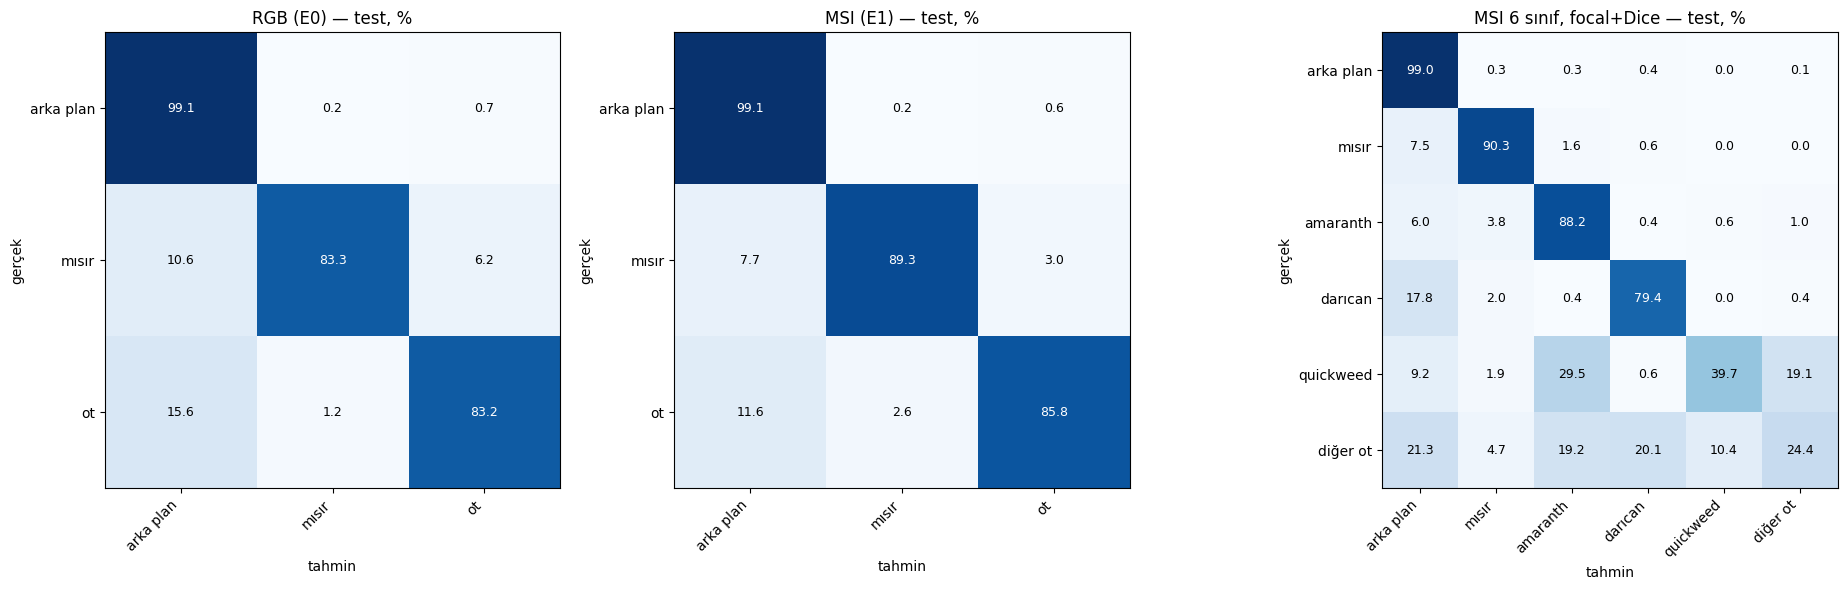

In [7]:
d = np.load(f'{o.RES_DIR}/test_cm.npy', allow_pickle=True).item()
CM = d['cm']

def cm_ciz(ax, cm, adlar, baslik):
    cmn = cm / cm.sum(1, keepdims=True)                      # satır = gerçek sınıf -> recall'a göre normalize
    ax.imshow(cmn, cmap='Blues', vmin=0, vmax=1)
    for i in range(len(adlar)):
        for j in range(len(adlar)):
            ax.text(j, i, f'{cmn[i, j]*100:.1f}', ha='center', va='center', fontsize=9,
                    color='white' if cmn[i, j] > 0.5 else 'black')
    ax.set_xticks(range(len(adlar)), adlar, rotation=45, ha='right'); ax.set_yticks(range(len(adlar)), adlar)
    ax.set_xlabel('tahmin'); ax.set_ylabel('gerçek'); ax.set_title(baslik)

fig, ax = plt.subplots(1, 3, figsize=(20, 6), gridspec_kw={'width_ratios': [1, 1, 1.6]})
cm_ciz(ax[0], CM['E0_rgb_3s'], o.SIN3, 'RGB (E0) — test, %')
cm_ciz(ax[1], CM['E1_msi_3s'], o.SIN3, 'MSI (E1) — test, %')
cm_ciz(ax[2], CM['E2_msi_6s_focal_dice'], o.SINIFLAR, 'MSI 6 sınıf, focal+Dice — test, %')
plt.tight_layout(); plt.savefig(f'{o.RES_DIR}/test_cm_karsilastirma.png', dpi=150); plt.show()

## 4. RGB ve MSI hata haritaları

MSI − RGB ot IoU farkı (görüntü başına):
2023-05-30_0114    -1.4
2023-06-06_0670     1.8
2023-06-06_0231     2.3
2023-06-06_0667     2.4
2023-06-06_0736     2.4
2023-06-06_0770     2.6
2023-06-06_0161     3.0
2023-06-15_0735     3.6
2023-06-15_0169     3.6
2023-05-30_0039     4.6
2023-05-25_0114     4.6
2023-06-06_0176     4.8
2023-06-06_0166     5.6
2023-05-30_0720     5.8
2023-05-30_0044     6.2
2023-05-30_0099     7.8
2023-05-30_0750     8.3
2023-05-30_0652     9.2
2023-05-25_0183     9.4
2023-05-30_0649    13.5
2023-05-25_0109    13.5
2023-05-25_0170    14.0
2023-05-25_0685    26.0
2023-05-25_0750    26.1
2023-05-25_0786    29.1
2023-05-25_0681    30.0


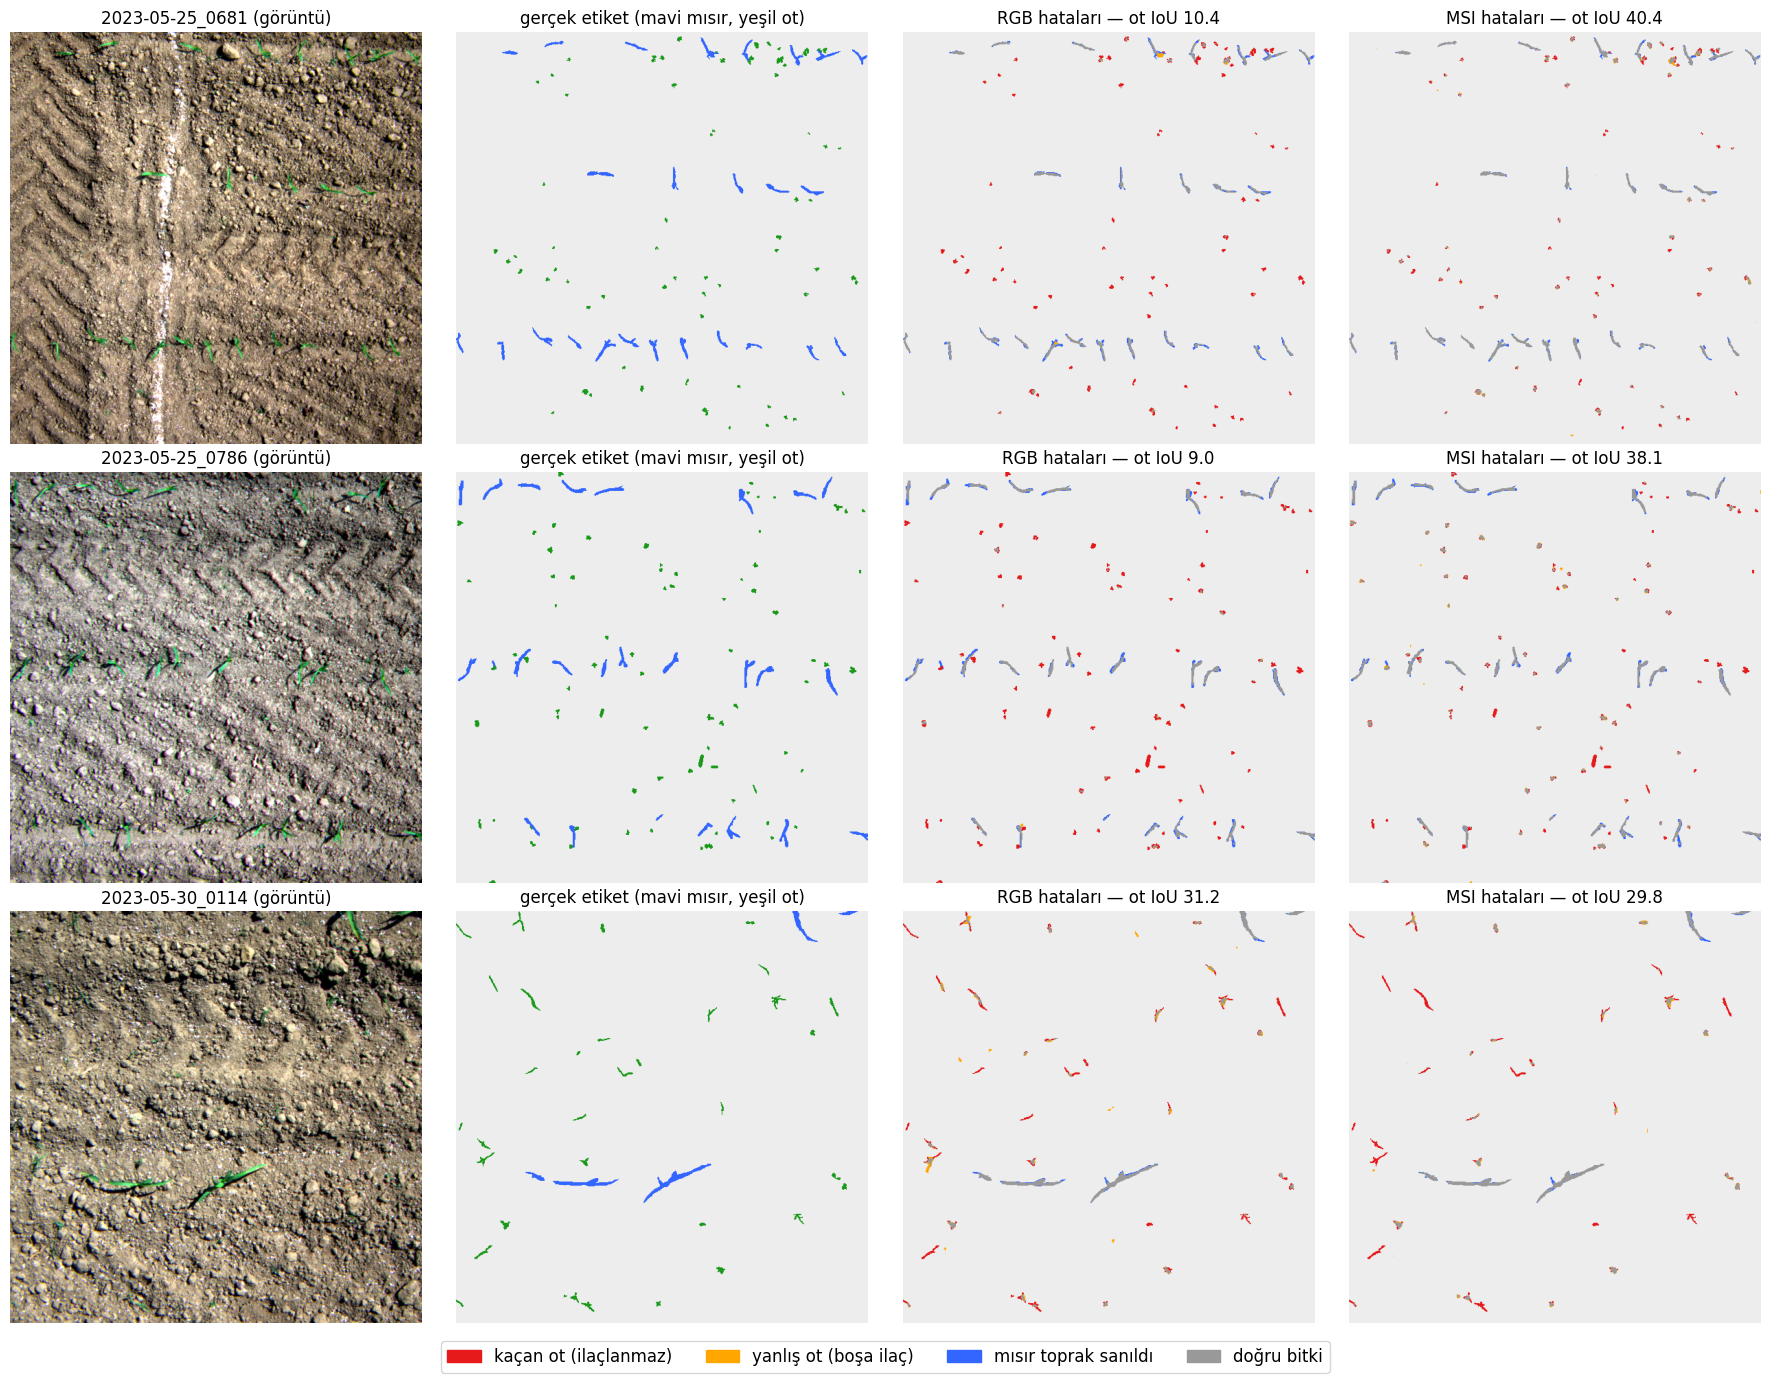

In [8]:
from matplotlib.patches import Patch

def tahminler(deney, kanal, ns):
    """Test görüntülerinin tahminlerini ve maskelerini döndürür (dolgu kırpılmış, 600×600)."""
    model = o.model_olustur(len(o.KANAL_SECIMI[kanal]), ns)
    model.load_state_dict(torch.load(f'{o.CKPT_DIR}/{deney}.pt', map_location=o.DEVICE))
    model = model.to(o.DEVICE).eval()
    ds = o.OtDataset(o.splits['test'], kanal, ns)
    P, Y = {}, {}
    with torch.no_grad():
        for i, ad in enumerate(o.splits['test']):
            x, y = ds[i]
            y = np.asarray(y)
            p = model(torch.as_tensor(x)[None].to(o.DEVICE)).argmax(1)[0].cpu().numpy()
            g = y != o.IGNORE                                         # dolgu olmayan bölge
            r, c = np.where(g.any(1))[0], np.where(g.any(0))[0]
            P[ad], Y[ad] = p[r[0]:r[-1]+1, c[0]:c[-1]+1], y[r[0]:r[-1]+1, c[0]:c[-1]+1]
    del model
    return P, Y

P_rgb, Y = tahminler('E0_rgb_3s', 'rgb', 3)
P_msi, _ = tahminler('E1_msi_3s', 'msi', 3)

def ot_iou(p, y):
    b = ((p == 2) | (y == 2)).sum()
    return ((p == 2) & (y == 2)).sum() / b if b else np.nan

fark = pd.Series({ad: ot_iou(P_msi[ad], Y[ad]) - ot_iou(P_rgb[ad], Y[ad]) for ad in Y}).dropna().sort_values()
print('MSI − RGB ot IoU farkı (görüntü başına):'); print((fark * 100).round(1).to_string())
secilen = list(fark.index[-2:][::-1]) + [fark.index[0]]          # MSI'nin en çok kazandığı 2 + en çok kaybettiği 1

def hata_haritasi(p, y):
    h = np.full(y.shape + (3,), 0.93)                              # doğru arka plan: açık gri
    h[(y > 0) & (p == y)] = 0.6                                    # doğru bitki: koyu gri
    h[(y == 1) & (p == 0)] = [0.2, 0.4, 1.0]                       # mısır kaçtı (toprak sanıldı): mavi
    h[(y == 2) & (p != 2)] = [0.9, 0.1, 0.1]                       # ot kaçtı -> ilaçlanmaz: kırmızı
    h[(p == 2) & (y != 2)] = [1.0, 0.65, 0.0]                      # yanlış ot -> boşa ilaç (mısırsa ürüne zarar): turuncu
    return h

RENK_GT = np.array([[0.93, 0.93, 0.93], [0.2, 0.4, 1.0], [0.1, 0.6, 0.1]])   # arka plan, mısır, ot
fig, ax = plt.subplots(len(secilen), 4, figsize=(18, 4.6 * len(secilen)))
for i, ad in enumerate(secilen):
    x = o.HAM[ad].astype(np.float32)
    rgb = np.stack([x[2], x[1], x[0]], -1)
    rgb = np.clip((rgb - np.percentile(rgb, 1)) / (np.percentile(rgb, 99) - np.percentile(rgb, 1)), 0, 1)
    ax[i, 0].imshow(rgb); ax[i, 0].set_title(f'{ad} (görüntü)')
    ax[i, 1].imshow(RENK_GT[Y[ad]]); ax[i, 1].set_title('gerçek etiket (mavi mısır, yeşil ot)')
    ax[i, 2].imshow(hata_haritasi(P_rgb[ad], Y[ad])); ax[i, 2].set_title(f'RGB hataları — ot IoU {ot_iou(P_rgb[ad], Y[ad])*100:.1f}')
    ax[i, 3].imshow(hata_haritasi(P_msi[ad], Y[ad])); ax[i, 3].set_title(f'MSI hataları — ot IoU {ot_iou(P_msi[ad], Y[ad])*100:.1f}')
    for a in ax[i]: a.axis('off')
fig.legend(handles=[Patch(color=[0.9, 0.1, 0.1], label='kaçan ot (ilaçlanmaz)'),
                    Patch(color=[1.0, 0.65, 0.0], label='yanlış ot (boşa ilaç)'),
                    Patch(color=[0.2, 0.4, 1.0], label='mısır toprak sanıldı'),
                    Patch(color='0.6', label='doğru bitki')], loc='lower center', ncol=4, fontsize=12)
plt.tight_layout(rect=[0, 0.03, 1, 1]); plt.savefig(f'{o.RES_DIR}/test_hata_haritalari.png', dpi=120); plt.show()

## 5. Quickweed ve amaranth karışıklığı

Test görüntülerinde quickweed piksel sayısı:
2023-06-06_0670    2840
2023-06-15_0735    1989
2023-06-06_0770    1750
2023-06-06_0231    1027
2023-06-06_0161     499
2023-06-06_0176     448
2023-05-30_0720     346
2023-06-06_0667     222
2023-05-30_0652     158
2023-05-30_0750     133
2023-05-25_0750      95
2023-05-25_0786      41


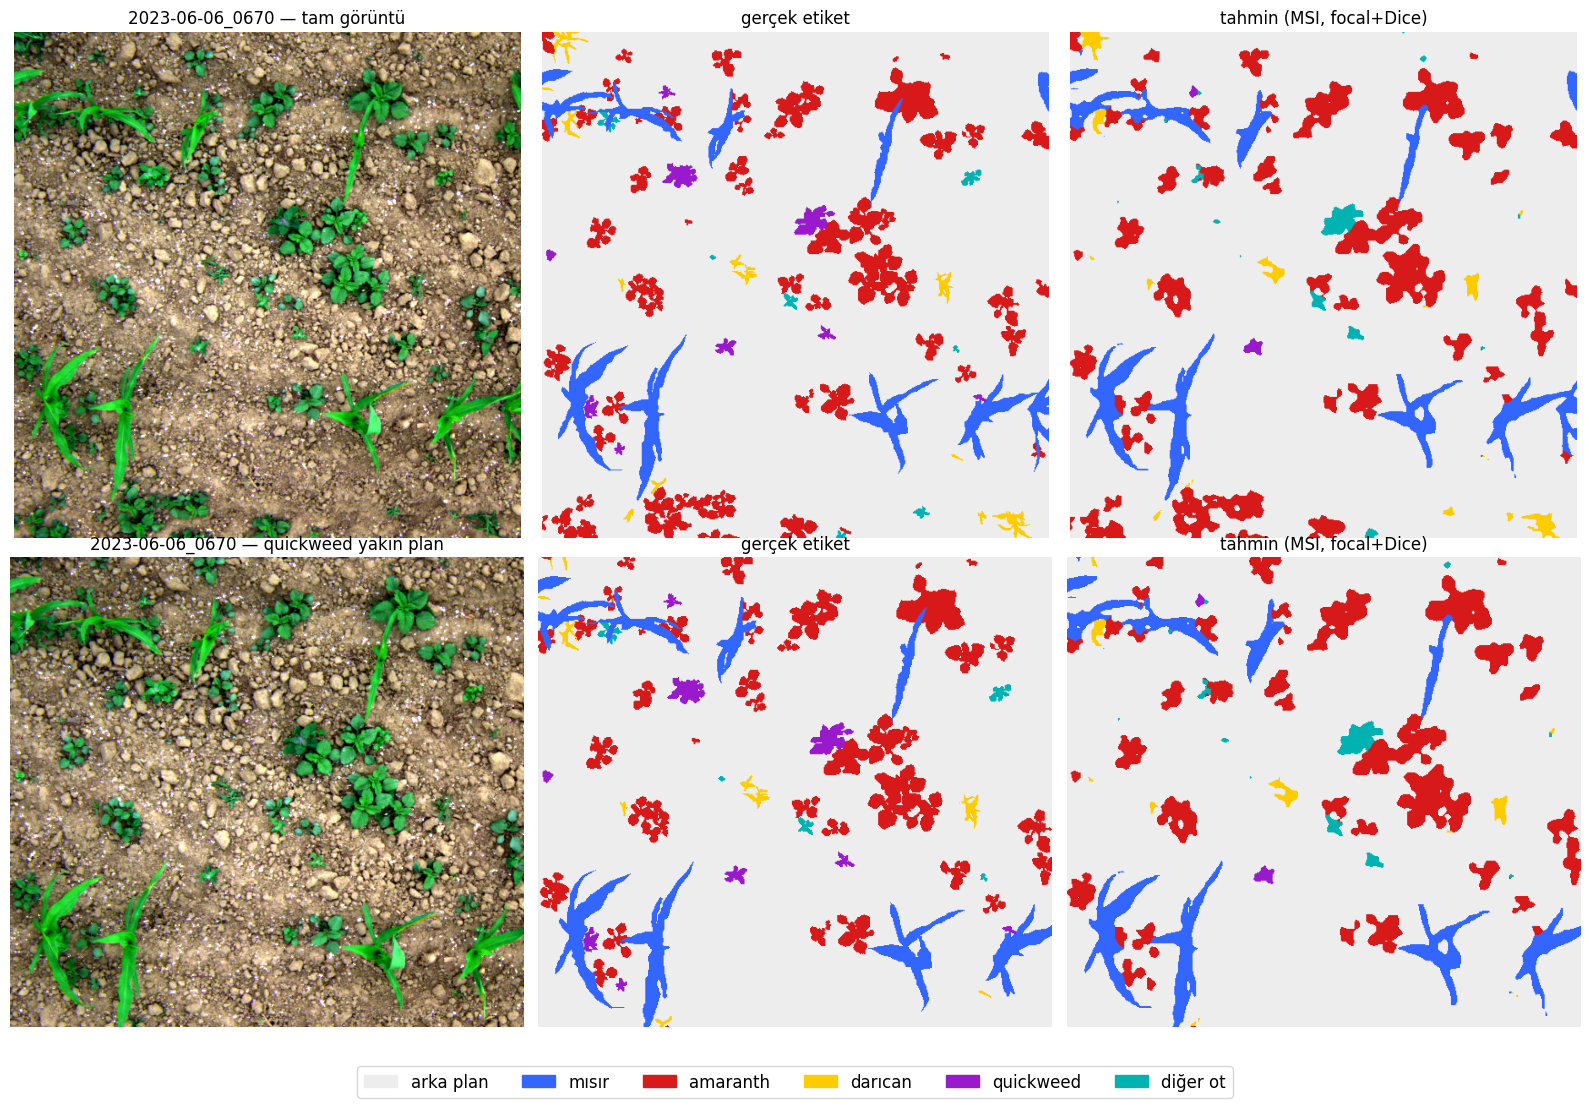

Bu görüntüde quickweed pikselleri nasıl tahmin edildi (%):
arka plan     8.2
mısır         3.8
amaranth     33.7
darıcan       0.0
quickweed    11.8
diğer ot     42.6


In [9]:
P6, Y6 = tahminler('E2_msi_6s_focal_dice', 'msi', 6)
qw = pd.Series({ad: (Y6[ad] == 4).sum() for ad in Y6}).sort_values(ascending=False)
print('Test görüntülerinde quickweed piksel sayısı:'); print(qw[qw > 0].to_string())
ad = qw.index[0]                                                   # en çok quickweed içeren görüntü

RENK6 = np.array([[0.93, 0.93, 0.93], [0.2, 0.4, 1.0], [0.85, 0.1, 0.1],   # arka plan, mısır, amaranth
                  [1.0, 0.8, 0.0], [0.6, 0.1, 0.8], [0.0, 0.7, 0.7]])      # darıcan, quickweed, diğer ot
r, c = np.where(Y6[ad] == 4)
r0, r1 = max(r.min() - 40, 0), min(r.max() + 40, 600)              # quickweed çevresine yakınlaştırma
c0, c1 = max(c.min() - 40, 0), min(c.max() + 40, 600)

x = o.HAM[ad].astype(np.float32)
rgb = np.stack([x[2], x[1], x[0]], -1)
rgb = np.clip((rgb - np.percentile(rgb, 1)) / (np.percentile(rgb, 99) - np.percentile(rgb, 1)), 0, 1)

fig, ax = plt.subplots(2, 3, figsize=(16, 11))
for i, (sl, etiket) in enumerate([((slice(None), slice(None)), 'tam görüntü'), ((slice(r0, r1), slice(c0, c1)), 'quickweed yakın plan')]):
    ax[i, 0].imshow(rgb[sl]); ax[i, 0].set_title(f'{ad} — {etiket}')
    ax[i, 1].imshow(RENK6[Y6[ad]][sl]); ax[i, 1].set_title('gerçek etiket')
    ax[i, 2].imshow(RENK6[P6[ad]][sl]); ax[i, 2].set_title('tahmin (MSI, focal+Dice)')
    for a in ax[i]: a.axis('off')
fig.legend(handles=[Patch(color=RENK6[k], label=s) for k, s in enumerate(o.SINIFLAR)], loc='lower center', ncol=6, fontsize=12)
plt.tight_layout(rect=[0, 0.04, 1, 1]); plt.savefig(f'{o.RES_DIR}/test_quickweed_hata.png', dpi=120); plt.show()

g = Y6[ad] == 4
print(f'Bu görüntüde quickweed pikselleri nasıl tahmin edildi (%):')
print(pd.Series(np.bincount(P6[ad][g], minlength=6) / g.sum() * 100, index=o.SINIFLAR).round(1).to_string())